# Assignment 16: Implementation of Value Iteration on a Markov Decision Process (MDP)
**Aim:** Implement value iteration on a 2-state, 2-action MDP (states `S1`, `S2`; actions `A1`, `A2`; discount factor γ = 0.9) using the Bellman optimality equation. Initialize V(s) = 0, display the value function after each iteration, and derive the final value function and the optimal policy.  
**Tools / Libraries:** `numpy`, `pandas`, `matplotlib`  
**Programming Platform / Language:** Jupyter Notebook, Python

## Theory & Task Overview

### Markov Decision Process (MDP) and Value Iteration
An MDP models sequential decision making using states, actions, transition probabilities, rewards, and a discount factor γ. **Value iteration** repeatedly applies the Bellman optimality update until the value function converges to the optimal value function V*:

$$V_{k+1}(s)=\max_a \big[\, R(s,a)+\gamma\, V_k(s')\,\big]$$

* **States:** `S1`, `S2`
* **Actions:** `A1`, `A2`
* **Discount factor:** γ = 0.9
* **Transition and reward model (deterministic):**

| State, Action | Next State | Reward |
|---|---|---|
| S1, A1 | S1 | 2 |
| S1, A2 | S2 | 5 |
| S2, A1 | S1 | 1 |
| S2, A2 | S2 | 3 |

* **Policy representation:** `0 → A1`, `1 → A2`. For each state, the policy picks the action with the maximum value.

## Step 1: Import Libraries and Define the MDP

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

states = ["S1", "S2"]
actions = ["A1", "A2"]
gamma = 0.9

# Deterministic model: (state, action) -> (next_state, reward)
# state index: S1=0, S2=1 ; action index: A1=0, A2=1
next_state = np.array([[0, 1],    # S1: A1->S1, A2->S2
                       [0, 1]])   # S2: A1->S1, A2->S2
reward = np.array([[2, 5],        # S1: A1=2, A2=5
                   [1, 3]])       # S2: A1=1, A2=3

print("MDP defined successfully!")
print("States :", states)
print("Actions:", actions)
print("Gamma  :", gamma)

MDP defined successfully!
States : ['S1', 'S2']
Actions: ['A1', 'A2']
Gamma  : 0.9


---
## Step 2: Value Iteration (Bellman Optimality Update)
We initialize **V(s) = 0** and update the values using the Bellman optimality equation. The value function is displayed after each iteration.

In [2]:
def bellman_update(V):
    V_new = np.zeros_like(V)
    for s in range(len(states)):
        # Q(s,a) = R(s,a) + gamma * V(s')
        q = [reward[s, a] + gamma * V[next_state[s, a]] for a in range(len(actions))]
        V_new[s] = max(q)
    return V_new

# 1. Initialize V(s) = 0
V = np.zeros(len(states))
num_iterations = 10      # iterations displayed (change if required)
history = [V.copy()]

# 2. Perform iterations and display value function after each one
print("=" * 50)
print("   VALUE FUNCTION AFTER EACH ITERATION   ")
print("=" * 50)
print(f"Iteration  0: V(S1) = {V[0]:.4f}, V(S2) = {V[1]:.4f}")
for k in range(1, num_iterations + 1):
    V = bellman_update(V)
    history.append(V.copy())
    print(f"Iteration {k:2d}: V(S1) = {V[0]:.4f}, V(S2) = {V[1]:.4f}")
print("=" * 50)

   VALUE FUNCTION AFTER EACH ITERATION   
Iteration  0: V(S1) = 0.0000, V(S2) = 0.0000
Iteration  1: V(S1) = 5.0000, V(S2) = 3.0000
Iteration  2: V(S1) = 7.7000, V(S2) = 5.7000
Iteration  3: V(S1) = 10.1300, V(S2) = 8.1300
Iteration  4: V(S1) = 12.3170, V(S2) = 10.3170
Iteration  5: V(S1) = 14.2853, V(S2) = 12.2853
Iteration  6: V(S1) = 16.0568, V(S2) = 14.0568
Iteration  7: V(S1) = 17.6511, V(S2) = 15.6511
Iteration  8: V(S1) = 19.0860, V(S2) = 17.0860
Iteration  9: V(S1) = 20.3774, V(S2) = 18.3774
Iteration 10: V(S1) = 21.5396, V(S2) = 19.5396


In [3]:
# 3. Continue until convergence to obtain the final value function
theta = 1e-6
k = num_iterations
while True:
    V_new = bellman_update(V)
    delta = np.max(np.abs(V_new - V))
    V = V_new
    history.append(V.copy())
    k += 1
    if delta < theta:
        break

print(f"Converged after {k} iterations.")

Converged after 143 iterations.


---
## Step 3: Final Value Function and Optimal Policy
For each state we choose the action with the maximum Q-value. Policy encoding: **0 → A1**, **1 → A2**.

In [4]:
policy = np.zeros(len(states), dtype=int)
q_rows = []
for s in range(len(states)):
    q = [reward[s, a] + gamma * V[next_state[s, a]] for a in range(len(actions))]
    q_rows.append(q)
    policy[s] = int(np.argmax(q))

print("=" * 50)
print("          FINAL RESULTS          ")
print("=" * 50)
print("Q-values for each state-action pair:")
print(pd.DataFrame(q_rows, index=states, columns=actions).round(4))

print("\nFinal Value Function:")
for s in range(len(states)):
    print(f"  V({states[s]}) = {V[s]:.4f}")

print("\nOptimal Policy (0 -> A1, 1 -> A2):", policy)
for s in range(len(states)):
    print(f"  {states[s]} -> {actions[policy[s]]}")
print("=" * 50)

          FINAL RESULTS          
Q-values for each state-action pair:
      A1    A2
S1  30.8  32.0
S2  29.8  30.0

Final Value Function:
  V(S1) = 32.0000
  V(S2) = 30.0000

Optimal Policy (0 -> A1, 1 -> A2): [1 1]
  S1 -> A2
  S2 -> A2


---
## Step 4: Visualizing Convergence
We plot how V(S1) and V(S2) evolve over the iterations.

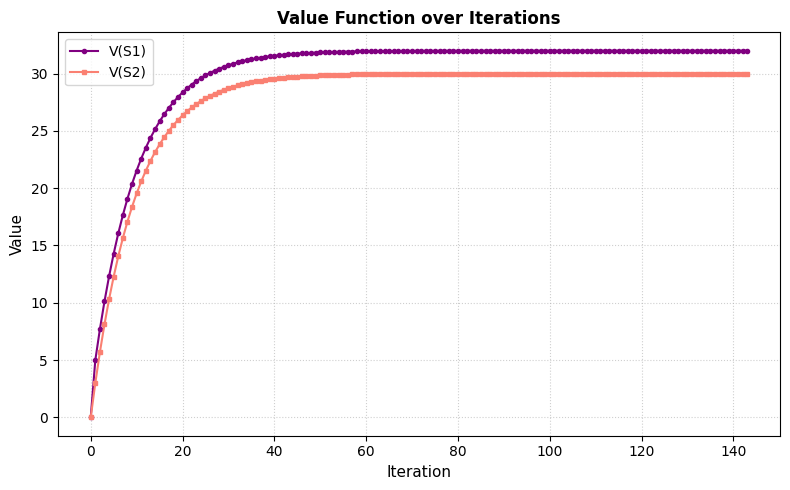

In [5]:
h = np.array(history)

plt.figure(figsize=(8, 5))
plt.plot(h[:, 0], marker='o', markersize=3, label='V(S1)', color='purple')
plt.plot(h[:, 1], marker='s', markersize=3, label='V(S2)', color='salmon')
plt.title('Value Function over Iterations', fontsize=12, fontweight='bold')
plt.xlabel('Iteration', fontsize=11)
plt.ylabel('Value', fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## Conclusion
* The value function converges to **V(S1) = 32** and **V(S2) = 30**, matching the analytical solution (V(S2) = 3 / (1 − 0.9) = 30, V(S1) = 5 + 0.9 × 30 = 32).
* The **optimal policy is [1, 1]**, i.e. choose **A2 in both states**.